 1. Chargement des données

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

columns = ["unit_id", "cycle", "setting_1", "setting_2", "setting_3"]
sensors = [f"sensor_{i}" for i in range(1, 22)]
columns += sensors

train = pd.read_csv(
    "../data/CMAPSSData/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)

last_cycle = train.groupby("unit_id")["cycle"].transform("max")
train["RUL"] = last_cycle - train["cycle"]

print(train.shape)
print(train["unit_id"].nunique(), "moteurs")
print(train.isna().sum().sum(), "valeurs manquantes")

(20631, 27)
100 moteurs
0 valeurs manquantes


## 2. Dimensions et qualité des données

On vérifie la taille du jeu de données, les doublons, les valeurs manquantes et l'ordre des cycles.

In [9]:
checks = {
    "doublons": train.duplicated().sum(),
    "valeurs manquantes": train.isna().sum().sum(),
    "cycles non croissants": (train.groupby("unit_id")["cycle"].diff() <= 0).sum(),
    "RUL négatifs": (train["RUL"] < 0).sum(),
}

pd.Series(checks)

doublons                 0
valeurs manquantes       0
cycles non croissants    0
RUL négatifs             0
dtype: int64

## 3. Analyse des trajectoires

Les moteurs ne fonctionnent pas tous pendant le même nombre de cycles.

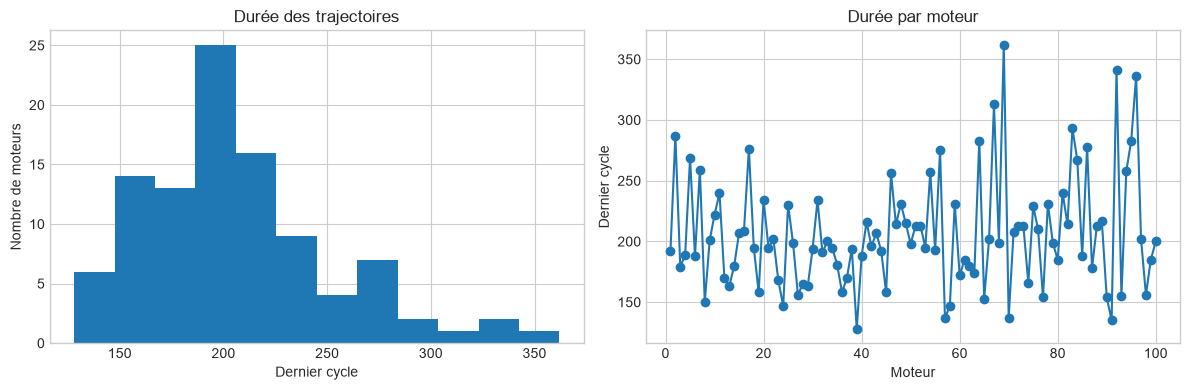

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

In [10]:
lengths = train.groupby("unit_id")["cycle"].max()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lengths, bins=12)
axes[0].set_title("Durée des trajectoires")
axes[0].set_xlabel("Dernier cycle")
axes[0].set_ylabel("Nombre de moteurs")

axes[1].plot(lengths.index, lengths.values, "o-")
axes[1].set_title("Durée par moteur")
axes[1].set_xlabel("Moteur")
axes[1].set_ylabel("Dernier cycle")

plt.tight_layout()
plt.show()

lengths.describe()

## 4. Capteurs et RUL

On classe les capteurs selon leur corrélation avec le RUL. Cela donne une première idée des capteurs utiles, sans parler de causalité.

In [ ]:
constant_sensors = train[sensors].nunique()
constant_sensors = constant_sensors[constant_sensors == 1].index.tolist()

correlations = train[sensors + ["RUL"]].corr()["RUL"].drop("RUL").dropna()
correlations = correlations.sort_values(key=np.abs, ascending=False)

print("Capteurs constants :", constant_sensors)
correlations

#  SI la correlation est proche de :
# - 1 : RUL a tendance à augmenter 
# - -1 : RUL  a tendance à diminuer

Capteurs constants : ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


sensor_11   -0.696228
sensor_4    -0.678948
sensor_12    0.671983
sensor_7     0.657223
sensor_15   -0.642667
sensor_21    0.635662
sensor_20    0.629428
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
Name: RUL, dtype: float64

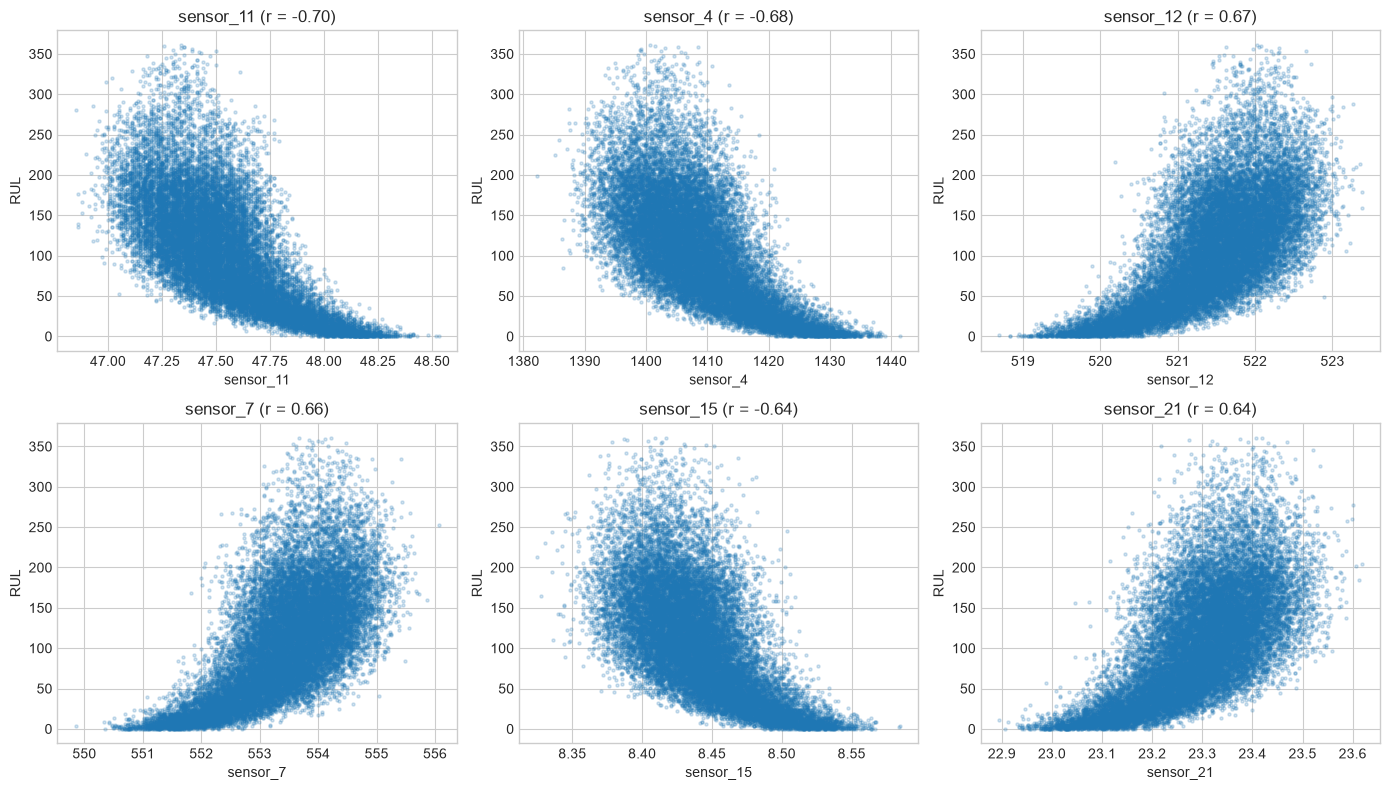

In [13]:
top_sensors = correlations.head(6).index
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, sensor in zip(axes.flat, top_sensors):
    ax.scatter(train[sensor], train["RUL"], s=5, alpha=0.2)
    ax.set_title(f"{sensor} (r = {correlations[sensor]:.2f})")
    ax.set_xlabel(sensor)
    ax.set_ylabel("RUL")

plt.tight_layout()
plt.show()

## 6. Conclusion

- Les trajectoires n'ont pas toutes la même longueur.
- Six capteurs sont constants dans FD001 et peuvent être retirés.
- Les capteurs les plus liés au RUL sont `sensor_11`, `sensor_4`, `sensor_12`, `sensor_7`, `sensor_15` et `sensor_21`.
- Les relations ne sont pas parfaitement linéaires, donc il faudra tester des modèles capables de gérer les courbes.